# Exploratory Data Analysis (EDA) — Used Car Market (CDS-75)

Simple exploratory data analysis covering the 4 core visuals:
1. **Selling Price Distribution** (`eda_01_selling_price_distribution.png`)
2. **Price vs Mileage Scatter & Correlation** (`eda_02_price_vs_mileage_scatter.png`)
3. **Price vs Vehicle Age Regression Trend** (`eda_03_price_vs_vehicle_age_regression.png`)
4. **Model Inventory Frequency & Brand Concentration** (`eda_04_model_frequency_and_brand_concentration.png`)

## 1. Load Dataset & Summary Statistics

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

# Load cleaned dataset and map brand from cardekho_cleaned.csv
df = pd.read_csv("../data/final_destination.csv")
brand_map = pd.read_csv("../data/cardekho_cleaned.csv", usecols=["model", "brand"]).drop_duplicates("model")
brand_map["brand"] = brand_map["brand"].replace({"ISUZU": "Isuzu"})
df = df.merge(brand_map, on="model", how="left")

# Convert price to Lakhs (1 Lakh = 100,000 INR) for easier reading on charts
df["price_lakhs"] = df["selling_price"] / 100000

print(f"Total rows: {len(df):,} | Columns: {df.shape[1]}")
df[["selling_price", "price_lakhs", "vehicle_age", "km_driven", "mileage"]].describe().round(2)

Total rows: 15,229 | Columns: 17


,selling_price,price_lakhs,vehicle_age,km_driven,mileage
count,15229.00,15229.00,15229.00,15229.00,15229.00
mean,774537.98,7.75,6.04,54887.83,19.70
std,894921.75,8.95,3.02,37065.08,4.17
min,40000.00,0.40,0.00,100.00,4.00
25%,385000.00,3.85,4.00,30000.00,17.00
50%,556000.00,5.56,6.00,50000.00,19.67
75%,825000.00,8.25,8.00,70000.00,22.70
max,39500000.00,395.00,29.00,830000.00,33.54


## 2. Selling Price Distribution (Histogram, Box Plot, KDE)

Mean Price:   7.75 Lakhs
Median Price: 5.56 Lakhs
Mode Price:   4.50 Lakhs


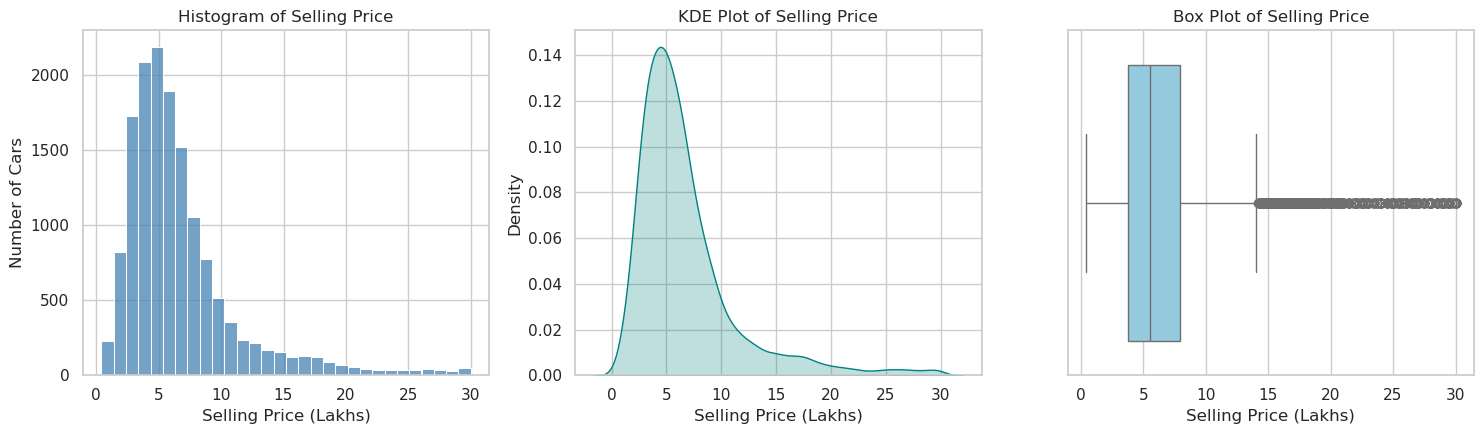

In [2]:
# Filter to <= 30 Lakhs (97% of cars) so the plots are easy to read without extreme luxury outliers
df_core = df[df["price_lakhs"] <= 30]

print(f"Mean Price:   {df['price_lakhs'].mean():.2f} Lakhs")
print(f"Median Price: {df['price_lakhs'].median():.2f} Lakhs")
print(f"Mode Price:   {df['price_lakhs'].mode()[0]:.2f} Lakhs")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Histogram
sns.histplot(df_core["price_lakhs"], bins=30, color="steelblue", ax=axes[0])
axes[0].set_title("Histogram of Selling Price")
axes[0].set_xlabel("Selling Price (Lakhs)")
axes[0].set_ylabel("Number of Cars")

# 2. KDE Plot
sns.kdeplot(df_core["price_lakhs"], fill=True, color="teal", ax=axes[1])
axes[1].set_title("KDE Plot of Selling Price")
axes[1].set_xlabel("Selling Price (Lakhs)")
axes[1].set_ylabel("Density")

# 3. Box Plot
sns.boxplot(x=df_core["price_lakhs"], color="skyblue", ax=axes[2])
axes[2].set_title("Box Plot of Selling Price")
axes[2].set_xlabel("Selling Price (Lakhs)")

plt.tight_layout()
plt.savefig("figures/eda_01_selling_price_distribution.png", dpi=300)
plt.show()

## 3. Price vs Mileage Scatter Plot & Correlation

Correlation (Selling Price vs km_driven): -0.1180
Correlation (Selling Price vs mileage kmpl): -0.3050


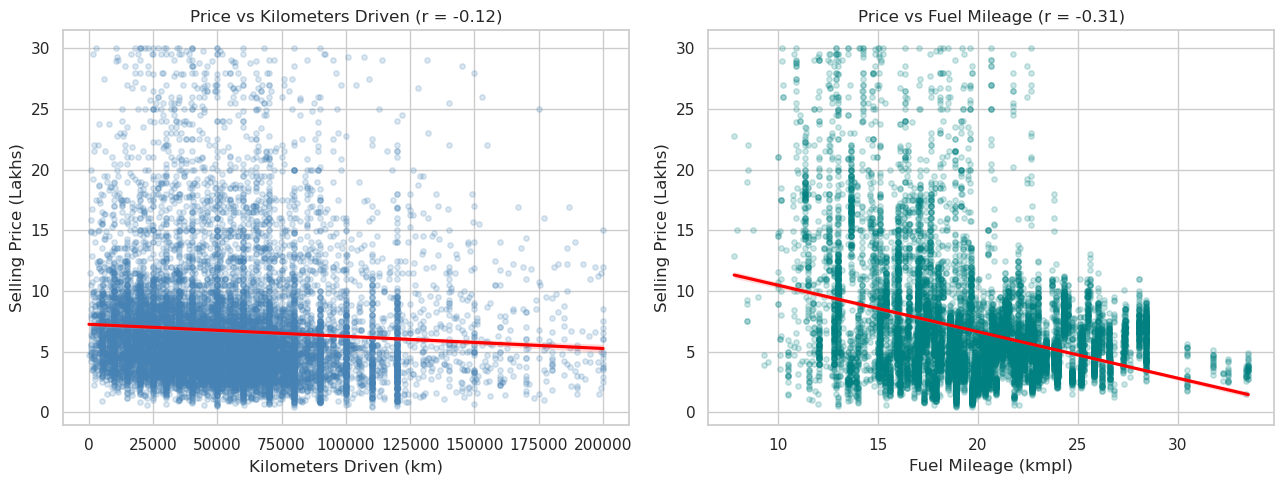

In [3]:
# Correlation coefficients
corr_km = df["selling_price"].corr(df["km_driven"])
corr_mileage = df["selling_price"].corr(df["mileage"])
print(f"Correlation (Selling Price vs km_driven): {corr_km:.4f}")
print(f"Correlation (Selling Price vs mileage kmpl): {corr_mileage:.4f}")

df_scatter = df[(df["price_lakhs"] <= 30) & (df["km_driven"] <= 200000)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Selling Price vs Odometer Driven (km_driven)
sns.regplot(
    data=df_scatter, x="km_driven", y="price_lakhs",
    scatter_kws={"alpha": 0.2, "s": 15, "color": "steelblue"},
    line_kws={"color": "red"}, ax=axes[0]
)
axes[0].set_title(f"Price vs Kilometers Driven (r = {corr_km:.2f})")
axes[0].set_xlabel("Kilometers Driven (km)")
axes[0].set_ylabel("Selling Price (Lakhs)")

# 2. Selling Price vs Fuel Efficiency (mileage kmpl)
sns.regplot(
    data=df_scatter, x="mileage", y="price_lakhs",
    scatter_kws={"alpha": 0.2, "s": 15, "color": "teal"},
    line_kws={"color": "red"}, ax=axes[1]
)
axes[1].set_title(f"Price vs Fuel Mileage (r = {corr_mileage:.2f})")
axes[1].set_xlabel("Fuel Mileage (kmpl)")
axes[1].set_ylabel("Selling Price (Lakhs)")

plt.tight_layout()
plt.savefig("figures/eda_02_price_vs_mileage_scatter.png", dpi=300)
plt.show()

## 4. Price vs Vehicle Age Regression Trend Line

Correlation (Selling Price vs Vehicle Age): -0.3115


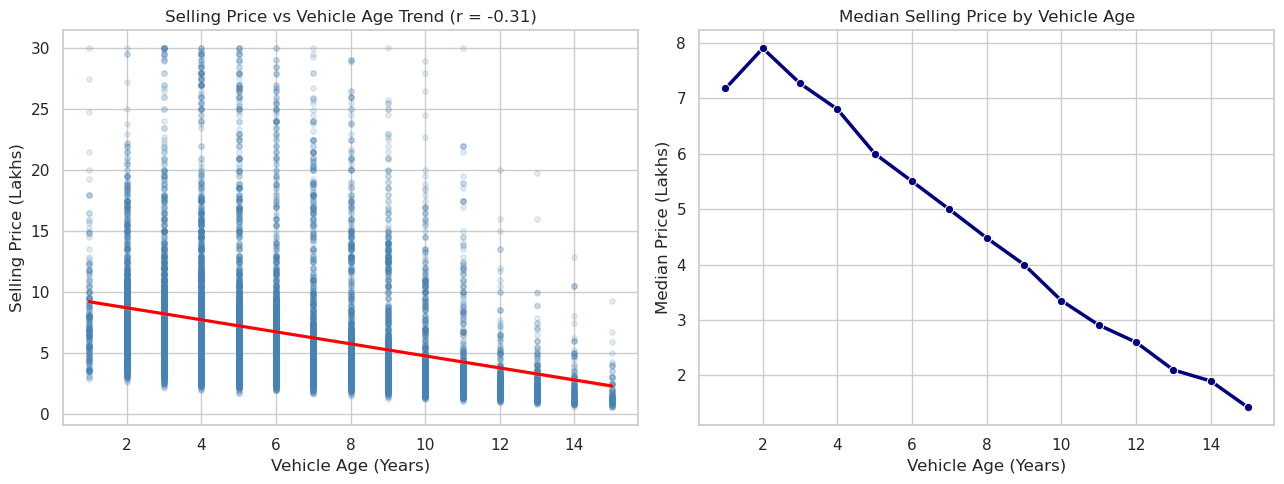

In [4]:
# Filter to reliable vehicle ages 1 to 15 (n >= 30)
df_age = df[(df["vehicle_age"].between(1, 15)) & (df["price_lakhs"] <= 30)]
corr_age = df_age["selling_price"].corr(df_age["vehicle_age"])
print(f"Correlation (Selling Price vs Vehicle Age): {corr_age:.4f}")

age_median = df_age.groupby("vehicle_age")["price_lakhs"].median().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Scatter + Linear Regression Trend Line
sns.regplot(
    data=df_age, x="vehicle_age", y="price_lakhs",
    scatter_kws={"alpha": 0.15, "s": 15, "color": "steelblue"},
    line_kws={"color": "red"}, ax=axes[0]
)
axes[0].set_title(f"Selling Price vs Vehicle Age Trend (r = {corr_age:.2f})")
axes[0].set_xlabel("Vehicle Age (Years)")
axes[0].set_ylabel("Selling Price (Lakhs)")

# 2. Median Selling Price by Vehicle Age
sns.lineplot(data=age_median, x="vehicle_age", y="price_lakhs", marker="o", linewidth=2.5, color="navy", ax=axes[1])
axes[1].set_title("Median Selling Price by Vehicle Age")
axes[1].set_xlabel("Vehicle Age (Years)")
axes[1].set_ylabel("Median Price (Lakhs)")

plt.tight_layout()
plt.savefig("figures/eda_03_price_vs_vehicle_age_regression.png", dpi=300)
plt.show()

## 5. Model Inventory Frequency & Brand Concentration

Top 5 Models (% of inventory):
model
i20            5.90
Swift Dzire    5.75
Swift          5.08
Alto           5.04
City           4.92
Name: proportion, dtype: float64

Top 5 Brands (% of inventory):
brand
Maruti      32.37
Hyundai     19.38
Honda        9.69
Mahindra     6.55
Toyota       5.16
Name: proportion, dtype: float64


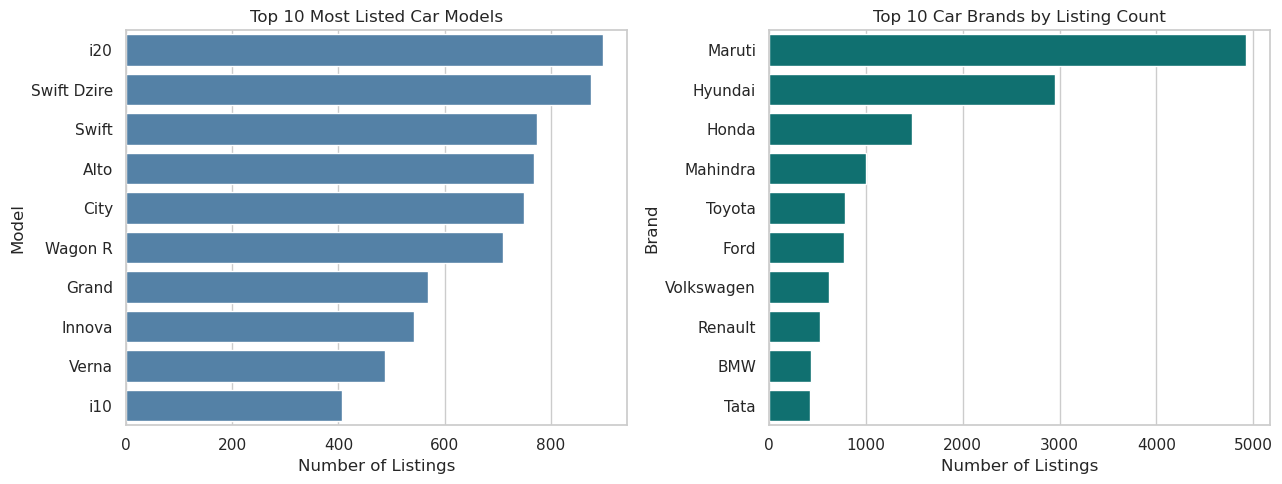

In [5]:
top_models = df["model"].value_counts().head(10)
top_brands = df["brand"].value_counts().head(10)

print("Top 5 Models (% of inventory):")
print((df["model"].value_counts(normalize=True).head(5) * 100).round(2))
print("\nTop 5 Brands (% of inventory):")
print((df["brand"].value_counts(normalize=True).head(5) * 100).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Top 10 Vehicle Models
sns.barplot(x=top_models.values, y=top_models.index, color="steelblue", ax=axes[0])
axes[0].set_title("Top 10 Most Listed Car Models")
axes[0].set_xlabel("Number of Listings")
axes[0].set_ylabel("Model")

# 2. Top 10 Car Brands
sns.barplot(x=top_brands.values, y=top_brands.index, color="teal", ax=axes[1])
axes[1].set_title("Top 10 Car Brands by Listing Count")
axes[1].set_xlabel("Number of Listings")
axes[1].set_ylabel("Brand")

plt.tight_layout()
plt.savefig("figures/eda_04_model_frequency_and_brand_concentration.png", dpi=300)
plt.show()